# 👥 Prediksi Karyawan yang Berisiko Keluar (Employee Attrition)

**Tujuan:** membuat model machine learning yang memperkirakan apakah seorang karyawan akan **keluar dari perusahaan** (`Attrition = Yes`) atau **bertahan** (`Attrition = No`). Hasilnya bisa membantu tim HR memantau karyawan yang berisiko lebih dulu.

**Prinsip yang kita pegang di notebook ini:**

| Prinsip | Artinya dengan bahasa sederhana |
|---|---|
| Split data lebih dulu | Pisahkan "soal latihan" dan "soal ujian" sebelum belajar apa pun, supaya penilaian jujur |
| Pakai `Pipeline` | Semua langkah persiapan data hanya belajar dari data latih |
| Pilih model dengan *cross-validation* | Data uji tidak dipakai untuk memilih model, hanya untuk penilaian akhir |
| Gunakan metrik yang tepat | Karena yang keluar hanya sedikit, kita lihat Recall, Precision, F1, dan AUC, bukan akurasi saja |
| Tangani data tidak seimbang | Pakai `class_weight` dan atur *threshold* (batas keputusan) |

**Alur notebook:** Import → Load data → Eksplorasi → Pembersihan → Split → Preprocessing → Bandingkan 2 model → Atur threshold → Uji akhir → Fitur penting → Simpan model → Inferensi pada data baru.

## 1️⃣ Import Library

Seperti menyiapkan alat sebelum memasak. Kita memanggil library untuk mengolah data (`pandas`, `numpy`), membuat grafik (`matplotlib`), dan membangun model (`scikit-learn`).

`RANDOM_STATE = 42` dipakai agar hasilnya **selalu sama** setiap kali notebook dijalankan ulang (*reproducible*).

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, average_precision_score, recall_score,
                             precision_score, f1_score, RocCurveDisplay,
                             PrecisionRecallDisplay, precision_recall_curve)
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
plt.rcParams["figure.figsize"] = (7, 4)
print("Library berhasil di-import ✅")

Library berhasil di-import ✅


## 2️⃣ Load Data

Kita membaca file CSV. File ini memakai pemisah titik koma (`;`) dan punya karakter tersembunyi di awal file (BOM), jadi kita pakai:
- `sep=None, engine="python"` → pandas menebak pemisahnya sendiri (koma atau titik koma sama-sama bisa).
- `encoding="utf-8-sig"` → membuang karakter BOM.

> 💡 **Pakai Google Colab?** Hapus tanda `#` pada dua baris pertama di sel di bawah untuk mengunggah file, atau unggah lewat panel Files di sebelah kiri. Kalau di komputer sendiri, cukup ubah `DATA_PATH` ke lokasi file kamu.

In [2]:
# from google.colab import files
# files.upload()   # pilih file WA_Fn-UseC_-HR-Employee-Attrition_1.csv

DATA_PATH = "WA_Fn-UseC_-HR-Employee-Attrition_1.csv"   # ubah jika file ada di folder lain

df = pd.read_csv(DATA_PATH, sep=None, engine="python", encoding="utf-8-sig")
print(f"Ukuran data: {df.shape[0]} baris dan {df.shape[1]} kolom")
df.head()

Ukuran data: 1470 baris dan 35 kolom


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


## 3️⃣ Eksplorasi Data (EDA)

Sebelum membuat model, kita kenali dulu datanya. Ibarat dokter yang memeriksa pasien sebelum memberi obat.

### 3.1 Cek kualitas data
Kita cek tiga hal: **nilai kosong** (missing), **baris kembar** (duplikat), dan **kolom yang isinya sama untuk semua orang** (konstan). Kolom konstan tidak berguna karena tidak bisa membedakan satu karyawan dengan yang lain.

In [3]:
print("Total nilai kosong     :", int(df.isnull().sum().sum()))
print("Jumlah baris duplikat  :", int(df.duplicated().sum()))

kolom_konstan = [c for c in df.columns if df[c].nunique() == 1]
print("Kolom konstan          :", kolom_konstan)

Total nilai kosong     : 0
Jumlah baris duplikat  : 0
Kolom konstan          : ['EmployeeCount', 'Over18', 'StandardHours']


### 3.2 Seberapa seimbang target kita?

Kolom target adalah `Attrition`. Kalau karyawan yang keluar jauh lebih sedikit daripada yang bertahan, datanya disebut **tidak seimbang (imbalanced)**.

Ini penting karena model bisa "malas": menebak *"semua karyawan bertahan"* saja sudah terlihat akurat, padahal tidak berguna untuk menemukan karyawan yang berisiko keluar.

,Jumlah,Persen (%)
Attrition,,
No,1233,83.9
Yes,237,16.1


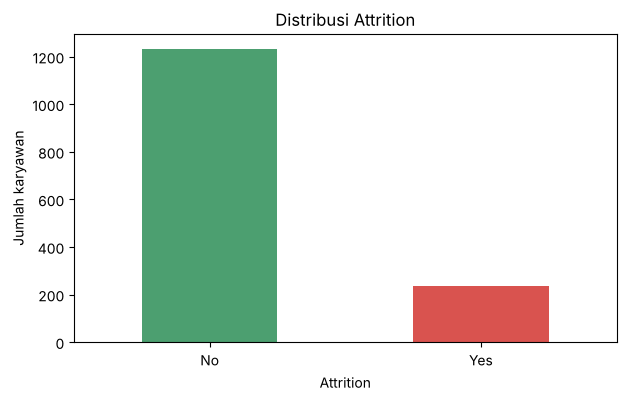


⚠️ Jika model menebak 'No' untuk semua orang, akurasinya sudah 83.9% tetapi ia tidak menemukan satu pun karyawan yang akan keluar.
Karena itu kita TIDAK boleh menilai model hanya dari akurasi.


In [4]:
hitung = df["Attrition"].value_counts()
persen = df["Attrition"].value_counts(normalize=True) * 100
display(pd.DataFrame({"Jumlah": hitung, "Persen (%)": persen.round(1)}))

hitung.plot(kind="bar", color=["#4C9F70", "#D9534F"])
plt.title("Distribusi Attrition")
plt.ylabel("Jumlah karyawan")
plt.xticks(rotation=0)
plt.show()

print(f"\n⚠️ Jika model menebak 'No' untuk semua orang, akurasinya sudah {persen['No']:.1f}% "
      "tetapi ia tidak menemukan satu pun karyawan yang akan keluar.")
print("Karena itu kita TIDAK boleh menilai model hanya dari akurasi.")

### 3.3 Faktor apa yang tampak berhubungan dengan karyawan keluar?

Sekilas, kita bandingkan **persentase karyawan yang keluar** pada beberapa kelompok. Ini baru gambaran awal, bukan bukti sebab-akibat.

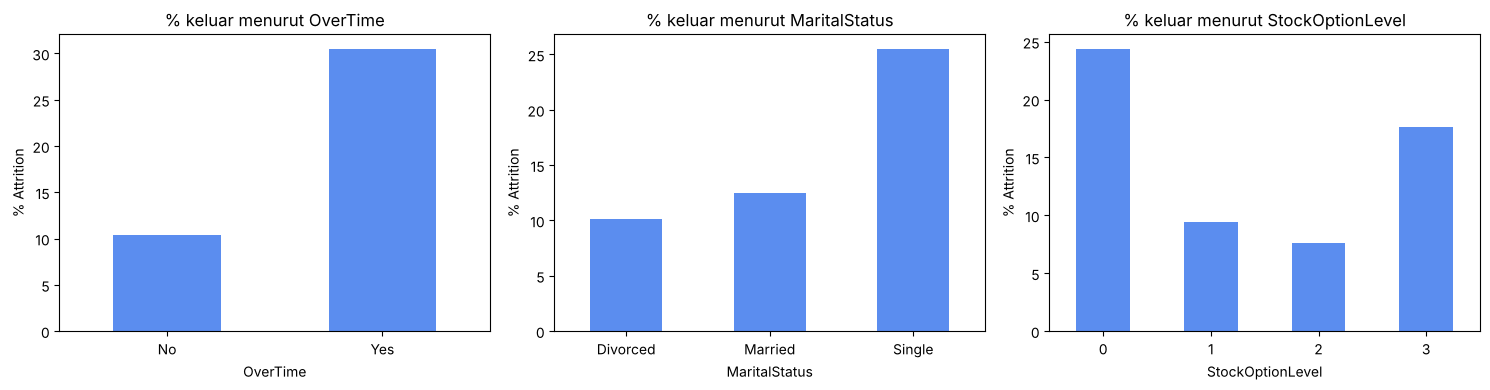

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, kolom in zip(axes, ["OverTime", "MaritalStatus", "StockOptionLevel"]):
    (df.groupby(kolom)["Attrition"].apply(lambda s: (s == "Yes").mean() * 100)
       .plot(kind="bar", ax=ax, color="#5B8DEF"))
    ax.set_title(f"% keluar menurut {kolom}")
    ax.set_ylabel("% Attrition")
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

## 4️⃣ Pembersihan Data

Hal yang kita lakukan:
1. **Hapus kolom konstan** (`EmployeeCount`, `Over18`, `StandardHours`): semua barisnya sama.
2. **Hapus `EmployeeNumber`**: ini hanya nomor ID, bukan sifat karyawan. Model bisa salah menganggapnya sebagai pola.
3. **Hapus baris duplikat** (jika ada).
4. **Ubah target** `Attrition` dari teks (`Yes`/`No`) menjadi angka (`1`/`0`).

> ✅ Langkah-langkah ini aman dilakukan sebelum split karena tidak "belajar" apa pun dari nilai data (hanya membuang kolom dan mengubah label). Langkah yang **menghitung statistik** (seperti scaling) harus menunggu sampai setelah split.

In [6]:
kolom_dibuang = kolom_konstan + ["EmployeeNumber"]
df_bersih = df.drop(columns=kolom_dibuang).drop_duplicates().reset_index(drop=True)

# Pisahkan fitur (X) dan target (y)
y = (df_bersih["Attrition"] == "Yes").astype(int)   # 1 = keluar, 0 = bertahan
X = df_bersih.drop(columns="Attrition")

print("Kolom yang dibuang:", kolom_dibuang)
print(f"Bentuk X: {X.shape} | Bentuk y: {y.shape}")

Kolom yang dibuang: ['EmployeeCount', 'Over18', 'StandardHours', 'EmployeeNumber']
Bentuk X: (1470, 30) | Bentuk y: (1470,)


## 5️⃣ Split Data: Train dan Test (**sebelum** preprocessing)

Bayangkan belajar untuk ujian:
- **Data latih (train, 80%)** = soal latihan yang boleh kita pelajari.
- **Data uji (test, 20%)** = soal ujian asli yang **tidak boleh diintip**.

Kalau kita mengintip soal ujian saat belajar, nilai kita jadi terlihat bagus padahal kemampuan aslinya belum tentu. Itulah **data leakage**.

`stratify=y` memastikan proporsi karyawan yang keluar sama di data latih dan data uji.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print(f"Data latih: {X_train.shape[0]} baris | % keluar = {y_train.mean()*100:.1f}%")
print(f"Data uji  : {X_test.shape[0]} baris | % keluar = {y_test.mean()*100:.1f}%")

Data latih: 1176 baris | % keluar = 16.2%
Data uji  : 294 baris | % keluar = 16.0%


### 5.1 Keterkaitan Antar Fitur (korelasi) — hanya data latih

Sebelum membuat model, kita periksa **fitur mana yang saling berkaitan**. Dua fitur yang sangat berkaitan membawa informasi yang hampir sama (*redundan*). Pada model linear seperti Logistic Regression, hal ini membuat koefisien sulit ditafsirkan.

| Pasangan fitur | Alat ukur | Rentang |
|---|---|---|
| Numerik – Numerik | Korelasi Pearson (*r*) | −1 sampai +1 |
| Kategori – Kategori / Kategori – Target | Cramér's V | 0 sampai 1 |

Ukuran baku yang sering dipakai: |*r*| ≥ 0,7 dianggap **berkaitan kuat**.

> ✅ Semua perhitungan di bagian ini memakai **`X_train`** saja. Data uji tidak disentuh, jadi tidak ada kebocoran data (*data leakage*).


Ditampilkan: 11 dari 23 fitur numerik.
Tidak ditampilkan (|r| < 0.3 dengan semua fitur lain, jadi hampir berdiri sendiri):
  ['DailyRate', 'DistanceFromHome', 'Education', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobSatisfaction', 'MonthlyRate', 'RelationshipSatisfaction', 'StockOptionLevel', 'TrainingTimesLastYear', 'WorkLifeBalance']



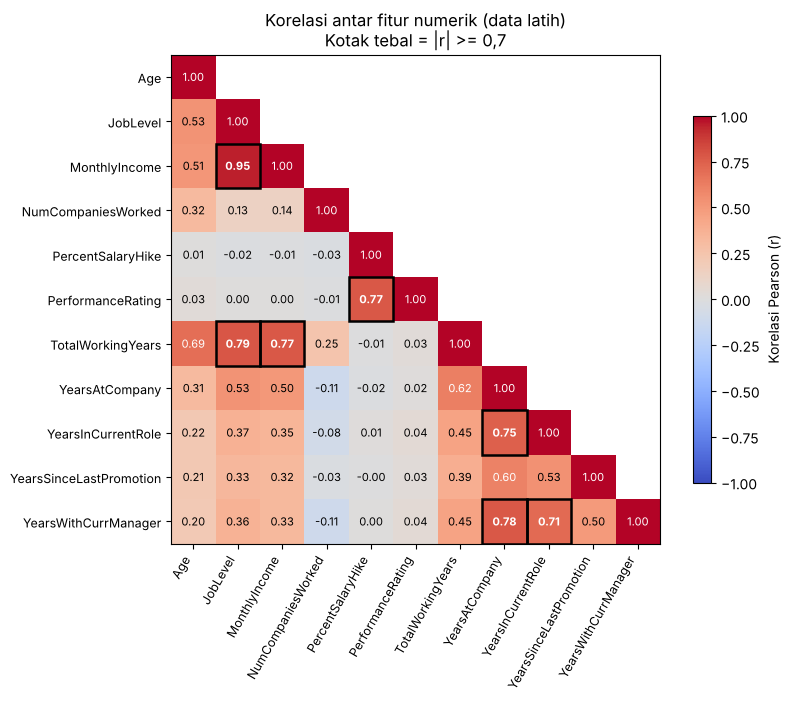

Pasangan fitur numerik dengan |r| >= 0.7:


,Fitur 1,Fitur 2,r
0,JobLevel,MonthlyIncome,0.947
1,JobLevel,TotalWorkingYears,0.785
2,YearsAtCompany,YearsWithCurrManager,0.776
3,MonthlyIncome,TotalWorkingYears,0.775
4,PercentSalaryHike,PerformanceRating,0.774
5,YearsAtCompany,YearsInCurrentRole,0.747
6,YearsInCurrentRole,YearsWithCurrManager,0.707


In [11]:
# --- Korelasi antar fitur NUMERIK (data latih saja) ---
num_cols = X_train.select_dtypes(include="number").columns.tolist()
korelasi = X_train[num_cols].corr()

# Dari 23 fitur numerik, banyak yang hampir tidak berkaitan dengan fitur lain.
# Heatmap hanya menampilkan fitur yang punya keterkaitan berarti (|r| >= 0.3) dengan minimal satu fitur lain.
BATAS_TAMPIL = 0.3
maks_r_lain = korelasi.where(~np.eye(len(num_cols), dtype=bool)).abs().max()
fitur_tampil = [c for c in num_cols if maks_r_lain[c] >= BATAS_TAMPIL]
fitur_sepi   = [c for c in num_cols if c not in fitur_tampil]
print(f"Ditampilkan: {len(fitur_tampil)} dari {len(num_cols)} fitur numerik.")
print(f"Tidak ditampilkan (|r| < {BATAS_TAMPIL} dengan semua fitur lain, jadi hampir berdiri sendiri):\n  {fitur_sepi}\n")

k = korelasi.loc[fitur_tampil, fitur_tampil]
mask_atas = np.triu(np.ones(k.shape, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(np.ma.array(k.values, mask=mask_atas), cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(k))); ax.set_xticklabels(k.columns, rotation=60, ha="right", fontsize=9)
ax.set_yticks(range(len(k))); ax.set_yticklabels(k.index, fontsize=9)
for i in range(len(k)):
    for j in range(i + 1):
        r = k.values[i, j]
        ax.text(j, i, f"{r:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(r) > 0.6 else "black", fontweight="bold" if abs(r) >= 0.7 and i != j else "normal")
        if abs(r) >= 0.7 and i != j:
            ax.add_patch(plt.Rectangle((j - .5, i - .5), 1, 1, fill=False, ec="black", lw=1.8))
plt.colorbar(im, shrink=0.75, label="Korelasi Pearson (r)")
ax.set_title("Korelasi antar fitur numerik (data latih)\nKotak tebal = |r| >= 0,7")
plt.tight_layout(); plt.show()

# Daftar pasangan dengan |r| >= 0.7 (dihitung dari SEMUA fitur numerik)
pasangan = korelasi.where(np.triu(np.ones(korelasi.shape, dtype=bool), k=1)).stack()
pasangan = pasangan.rename_axis(["Fitur 1", "Fitur 2"]).rename("r").reset_index()
pasangan = pasangan[pasangan["r"].abs() >= 0.7].sort_values("r", key=abs, ascending=False)
print("Pasangan fitur numerik dengan |r| >= 0.7:")
display(pasangan.round(3).reset_index(drop=True))


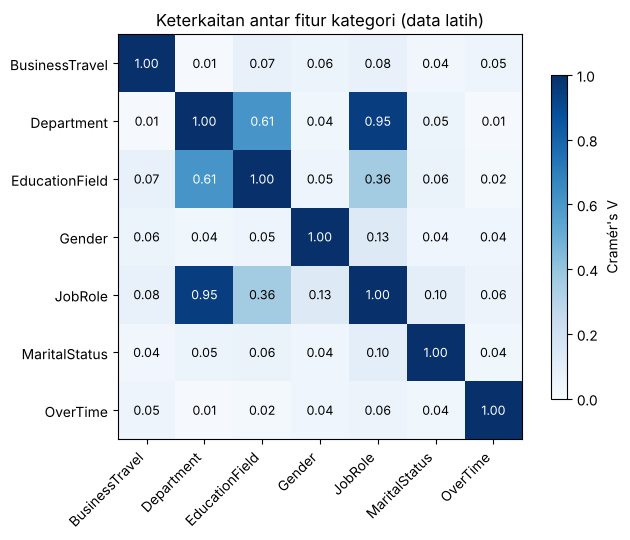

Pasangan fitur kategori dengan Cramér's V >= 0.3:


,Fitur 1,Fitur 2,Cramér's V
0,Department,JobRole,0.945
1,Department,EducationField,0.606
2,EducationField,JobRole,0.356


In [12]:
# --- Keterkaitan antar fitur KATEGORI (Cramér's V, data latih saja) ---
from scipy.stats import chi2_contingency

def cramers_v(a, b):
    tabel = pd.crosstab(a, b)
    chi2 = chi2_contingency(tabel, correction=False)[0]
    n = tabel.values.sum()
    k = min(tabel.shape) - 1
    return float(np.sqrt(chi2 / (n * k))) if k > 0 else 0.0

cat_cols = X_train.select_dtypes(exclude="number").columns.tolist()
V = pd.DataFrame([[cramers_v(X_train[a], X_train[b]) for b in cat_cols] for a in cat_cols],
                 index=cat_cols, columns=cat_cols)

fig, ax = plt.subplots(figsize=(7, 5.5))
im = ax.imshow(V.values, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(cat_cols))); ax.set_xticklabels(cat_cols, rotation=45, ha="right")
ax.set_yticks(range(len(cat_cols))); ax.set_yticklabels(cat_cols)
for i in range(len(cat_cols)):
    for j in range(len(cat_cols)):
        ax.text(j, i, f"{V.values[i, j]:.2f}", ha="center", va="center",
                color="white" if V.values[i, j] > 0.5 else "black", fontsize=9)
plt.colorbar(im, shrink=0.8, label="Cramér's V")
ax.set_title("Keterkaitan antar fitur kategori (data latih)")
plt.tight_layout(); plt.show()

pasangan_cat = V.where(np.triu(np.ones(V.shape, dtype=bool), k=1)).stack()
pasangan_cat = pasangan_cat.rename_axis(["Fitur 1", "Fitur 2"]).rename("Cramér's V").reset_index()
print("Pasangan fitur kategori dengan Cramér's V >= 0.3:")
display(pasangan_cat[pasangan_cat["Cramér's V"] >= 0.3].sort_values("Cramér's V", ascending=False).round(3).reset_index(drop=True))


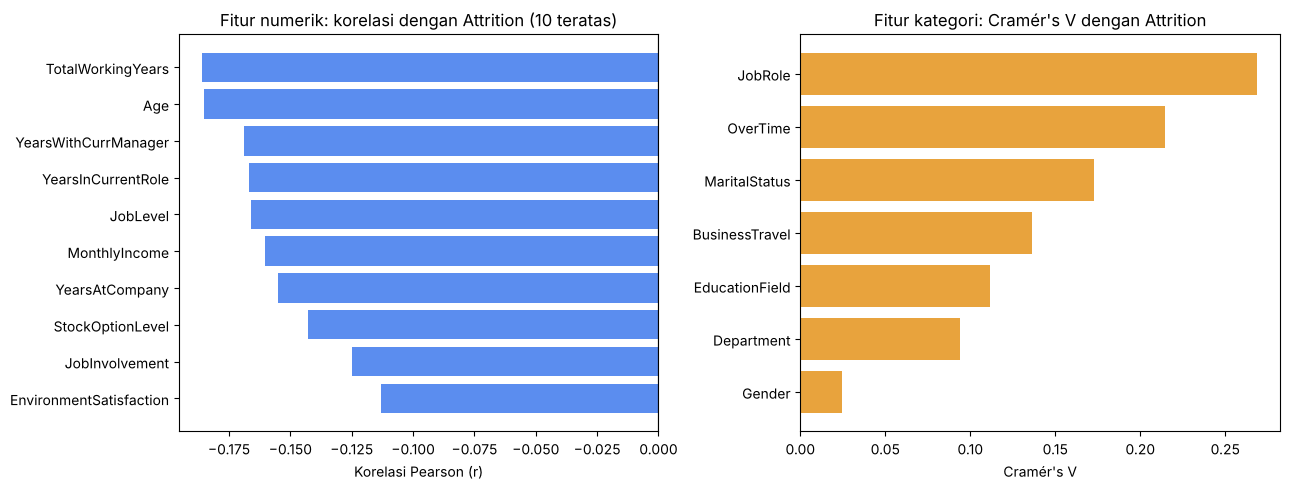

Korelasi numerik terlemah dengan Attrition (|r| terkecil):


,r
PerformanceRating,0.007
PercentSalaryHike,-0.009
HourlyRate,-0.019
MonthlyRate,0.022
Education,-0.030


In [13]:
# --- Keterkaitan tiap fitur dengan TARGET (Attrition), data latih saja ---
r_target = X_train[num_cols].corrwith(y_train)                       # numerik: Pearson dengan target 0/1
v_target = pd.Series({c: cramers_v(X_train[c], y_train) for c in cat_cols})   # kategori: Cramér's V

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
r10 = r_target.reindex(r_target.abs().sort_values(ascending=False).index).head(10).iloc[::-1]
axes[0].barh(r10.index, r10.values, color=np.where(r10.values < 0, "#5B8DEF", "#D9534F"))
axes[0].axvline(0, color="black", lw=0.8)
axes[0].set_title("Fitur numerik: korelasi dengan Attrition (10 teratas)")
axes[0].set_xlabel("Korelasi Pearson (r)")

v_sorted = v_target.sort_values()
axes[1].barh(v_sorted.index, v_sorted.values, color="#E8A33D")
axes[1].set_title("Fitur kategori: Cramér's V dengan Attrition")
axes[1].set_xlabel("Cramér's V")
plt.tight_layout(); plt.show()

print("Korelasi numerik terlemah dengan Attrition (|r| terkecil):")
display(r_target.reindex(r_target.abs().sort_values().index).head(5).round(3).to_frame("r"))


**Cara membaca hasilnya:**

- **Fitur numerik yang berkaitan kuat (|r| ≥ 0,7):** `MonthlyIncome`–`JobLevel` (0,95), `JobLevel`–`TotalWorkingYears` (0,79), `YearsAtCompany`–`YearsWithCurrManager` (0,78), `MonthlyIncome`–`TotalWorkingYears` (0,78), `PercentSalaryHike`–`PerformanceRating` (0,77), `YearsAtCompany`–`YearsInCurrentRole` (0,75), `YearsInCurrentRole`–`YearsWithCurrManager` (0,71). Artinya gaji, level jabatan, dan lama bekerja bergerak bersama.
- **Fitur kategori:** `Department` dan `JobRole` hampir identik (Cramér's V = 0,95), karena setiap jabatan hanya ada di satu departemen. `EducationField`–`Department` juga cukup kuat (0,61).
- **Keterkaitan dengan target:** tidak ada fitur numerik yang menonjol. Yang terkuat hanya |*r*| ≈ 0,19 (`TotalWorkingYears` dan `Age`, keduanya negatif: makin senior, makin kecil peluang keluar). Yang hampir nol: `PerformanceRating`, `PercentSalaryHike`, `HourlyRate`, `MonthlyRate`. Pada fitur kategori, `JobRole` (0,27) dan `OverTime` (0,21) paling berkaitan dengan target.

**Apa dampaknya?**

- Pada Logistic Regression, fitur yang berkaitan kuat membuat koefisien tidak stabil dan sulit ditafsirkan satu per satu. Karena itu pengaruh satu fitur jangan dibaca terpisah dari pasangannya.
- Fitur yang redundan atau tidak berguna dibuang di bagian 5.2 di bawah ini.
- Korelasi menunjukkan *keterkaitan*, bukan *sebab-akibat*.


### 5.2 Seleksi Fitur: Buang Fitur yang Tidak Berguna

Fitur yang terlalu banyak membuat model lebih rumit, sulit dijelaskan, dan memaksa HR mengisi data yang sebenarnya tidak membantu. Kita buang fitur dengan **tiga aturan**, keduanya hanya memakai **data latih**:

| Aturan | Yang dibuang | Alasan |
|---|---|---|
| 1. Redundan | Dari tiap pasangan fitur yang berkaitan kuat (numerik \|*r*\| ≥ 0,7; kategori Cramér's V ≥ 0,9), buang yang **hubungannya dengan target lebih lemah** | Dua fitur kembar membawa informasi yang sama |
| 2. Tidak berguna (L1 / Lasso) | Fitur yang **semua koefisiennya dinolkan** oleh Logistic Regression berpenalti L1 | L1 secara otomatis menyingkirkan fitur yang tidak menambah daya prediksi |
| 3. Numerik yang tidak menambah performa | Fitur numerik yang bila dibuang **tidak menurunkan PR-AUC** (*backward elimination* dengan CV berulang) | Banyak fitur numerik hanya menambah *noise*. Pembuangan berhenti ketika PR-AUC turun lebih dari 0,005 |

> ✅ Daftar fitur yang dibuang ditentukan dari **`X_train`** saja, lalu kolom yang sama dibuang dari `X_test`. Data uji tidak dipakai untuk memilih fitur.


In [14]:
# --- Aturan 1: buang fitur REDUNDAN (data latih saja) ---
kekuatan_target = pd.concat([r_target.abs(), v_target])   # seberapa kuat tiap fitur berhubungan dengan target

fitur_redundan = []
pasangan_kuat = (
    [(a, b, abs(r)) for a, b, r in pasangan[["Fitur 1", "Fitur 2", "r"]].itertuples(index=False)] +
    [(a, b, v) for a, b, v in pasangan_cat[pasangan_cat["Cramér's V"] >= 0.9][["Fitur 1", "Fitur 2", "Cramér's V"]].itertuples(index=False)]
)
for a, b, nilai in sorted(pasangan_kuat, key=lambda t: -t[2]):
    if a in fitur_redundan or b in fitur_redundan:
        continue                     # salah satunya sudah dibuang, pasangan ini tidak perlu diproses lagi
    buang, simpan = (a, b) if kekuatan_target[a] < kekuatan_target[b] else (b, a)
    fitur_redundan.append(buang)
    print(f"Buang {buang:<22} (berkaitan {nilai:.2f} dengan {simpan}, yang lebih kuat terhadap target)")

print("\nFitur redundan yang dibuang:", fitur_redundan)


Buang MonthlyIncome          (berkaitan 0.95 dengan JobLevel, yang lebih kuat terhadap target)
Buang Department             (berkaitan 0.95 dengan JobRole, yang lebih kuat terhadap target)
Buang JobLevel               (berkaitan 0.79 dengan TotalWorkingYears, yang lebih kuat terhadap target)
Buang YearsAtCompany         (berkaitan 0.78 dengan YearsWithCurrManager, yang lebih kuat terhadap target)
Buang PerformanceRating      (berkaitan 0.77 dengan PercentSalaryHike, yang lebih kuat terhadap target)
Buang YearsInCurrentRole     (berkaitan 0.71 dengan YearsWithCurrManager, yang lebih kuat terhadap target)

Fitur redundan yang dibuang: ['MonthlyIncome', 'Department', 'JobLevel', 'YearsAtCompany', 'PerformanceRating', 'YearsInCurrentRole']


Fitur yang dinolkan L1 (tidak berguna): ['Education', 'HourlyRate', 'MonthlyRate']


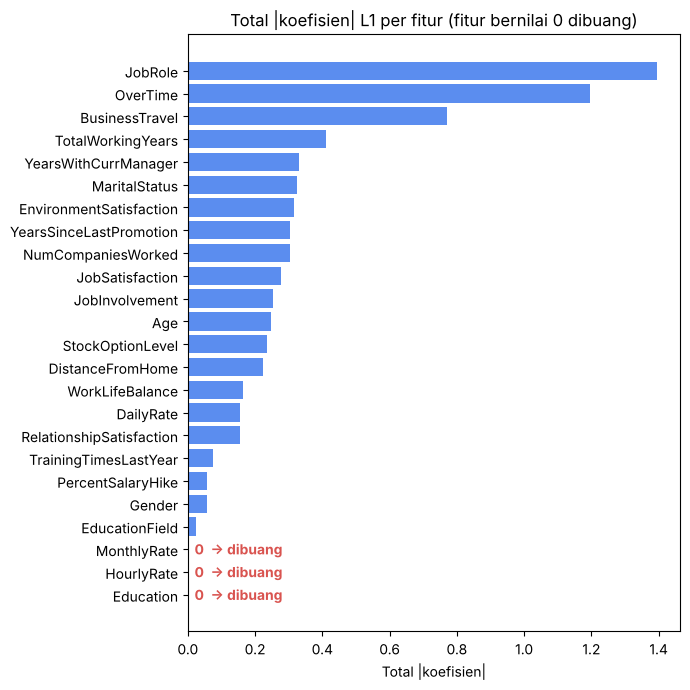

In [15]:
# --- Aturan 2: buang fitur TIDAK BERGUNA dengan L1 / Lasso (data latih saja) ---
sisa = [c for c in X_train.columns if c not in fitur_redundan]
num_sisa = [c for c in sisa if c in num_cols]
cat_sisa = [c for c in sisa if c in cat_cols]

prep_l1 = ColumnTransformer([
    ("num", StandardScaler(), num_sisa),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_sisa),
])
Z = prep_l1.fit_transform(X_train[sisa])
lasso = LogisticRegression(penalty="l1", solver="liblinear", C=0.1,
                           class_weight="balanced", random_state=RANDOM_STATE).fit(Z, y_train)

koef = pd.Series(lasso.coef_[0], index=prep_l1.get_feature_names_out())

def fitur_asal(nama_kolom):
    """Kembalikan nama fitur asli dari nama kolom hasil encoding."""
    jenis, nama = nama_kolom.split("__", 1)
    if jenis == "num":
        return nama
    return max((c for c in cat_sisa if nama.startswith(c + "_")), key=len)

total_koef = koef.abs().groupby(fitur_asal).sum()
fitur_l1_nol = sorted(total_koef[total_koef == 0].index.tolist())
print("Fitur yang dinolkan L1 (tidak berguna):", fitur_l1_nol)

urut = total_koef.sort_values()
fig, ax = plt.subplots(figsize=(7, 7))
ax.barh(urut.index, urut.values, color="#5B8DEF")
for y_pos, (nama, nilai) in enumerate(urut.items()):
    if nilai == 0:
        ax.text(0.02, y_pos, "0  → dibuang", va="center", color="#D9534F", fontweight="bold")
ax.set_title("Total |koefisien| L1 per fitur (fitur bernilai 0 dibuang)")
ax.set_xlabel("Total |koefisien|")
plt.tight_layout(); plt.show()


Awal: 15 fitur numerik, PR-AUC = 0.633  (batas minimum = 0.628)



Buang PercentSalaryHike          -> 14 numerik, PR-AUC = 0.641


Buang DailyRate                  -> 13 numerik, PR-AUC = 0.644


Buang TotalWorkingYears          -> 12 numerik, PR-AUC = 0.641


Buang StockOptionLevel           -> 11 numerik, PR-AUC = 0.639


Buang YearsSinceLastPromotion    -> 10 numerik, PR-AUC = 0.634


Buang RelationshipSatisfaction   ->  9 numerik, PR-AUC = 0.631


Berhenti: membuang TrainingTimesLastYear menurunkan PR-AUC menjadi 0.621 (di bawah batas).

Fitur numerik dibuang  : ['PercentSalaryHike', 'DailyRate', 'TotalWorkingYears', 'StockOptionLevel', 'YearsSinceLastPromotion', 'RelationshipSatisfaction']
Fitur numerik dipertahankan: ['Age', 'DistanceFromHome', 'EnvironmentSatisfaction', 'JobInvolvement', 'JobSatisfaction', 'NumCompaniesWorked', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsWithCurrManager']


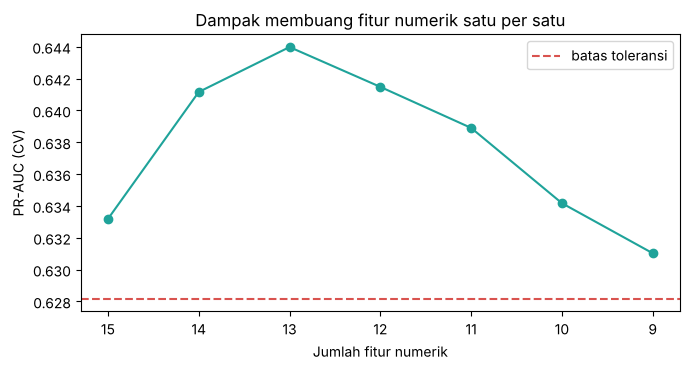

In [16]:
# --- Aturan 3: buang fitur NUMERIK yang tidak menambah performa (backward elimination, data latih saja) ---
# Cara kerja: dari semua fitur numerik yang tersisa, coba buang satu per satu. Buang yang paling TIDAK merugikan
# PR-AUC (cross-validation berulang di data latih). Ulangi sampai performa mulai turun lebih dari batas toleransi.
from sklearn.model_selection import RepeatedStratifiedKFold

sisa_setelah_l1 = [c for c in sisa if c not in fitur_l1_nol]
num_kini = [c for c in sisa_setelah_l1 if c in num_cols]
cat_kini = [c for c in sisa_setelah_l1 if c in cat_cols]       # fitur kategori tidak diubah di langkah ini

cv_ulang = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)

def pr_auc_cv(num_pakai):
    pipe = Pipeline([
        ("prep", ColumnTransformer([("num", StandardScaler(), num_pakai),
                                    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_kini)])),
        ("model", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE)),
    ])
    return cross_validate(pipe, X_train[num_pakai + cat_kini], y_train, cv=cv_ulang,
                          scoring="average_precision")["test_score"].mean()

TOLERANSI = 0.005                      # boleh turun paling banyak 0,005 dari PR-AUC awal
pr_awal = pr_auc_cv(num_kini)
print(f"Awal: {len(num_kini)} fitur numerik, PR-AUC = {pr_awal:.3f}  (batas minimum = {pr_awal - TOLERANSI:.3f})\n")

fitur_numerik_dibuang, riwayat = [], [(len(num_kini), pr_awal)]
while len(num_kini) > 1:
    kandidat = {f: pr_auc_cv([c for c in num_kini if c != f]) for f in num_kini}
    f_buang = max(kandidat, key=kandidat.get)                     # yang paling sedikit merugikan
    if kandidat[f_buang] < pr_awal - TOLERANSI:
        print(f"Berhenti: membuang {f_buang} menurunkan PR-AUC menjadi {kandidat[f_buang]:.3f} (di bawah batas).")
        break
    num_kini.remove(f_buang); fitur_numerik_dibuang.append(f_buang)
    riwayat.append((len(num_kini), kandidat[f_buang]))
    print(f"Buang {f_buang:<26} -> {len(num_kini):>2} numerik, PR-AUC = {kandidat[f_buang]:.3f}")

print("\nFitur numerik dibuang  :", fitur_numerik_dibuang)
print("Fitur numerik dipertahankan:", num_kini)

jml, pr = zip(*riwayat)
plt.figure(figsize=(7, 3.8))
plt.plot(jml, pr, marker="o", color="#1FA39A")
plt.axhline(pr_awal - TOLERANSI, color="#D9534F", ls="--", label="batas toleransi")
plt.gca().invert_xaxis()
plt.xlabel("Jumlah fitur numerik"); plt.ylabel("PR-AUC (CV)")
plt.title("Dampak membuang fitur numerik satu per satu"); plt.legend()
plt.tight_layout(); plt.show()


In [17]:
# --- Terapkan seleksi + cek dampaknya ---
fitur_dibuang = sorted(set(fitur_redundan) | set(fitur_l1_nol) | set(fitur_numerik_dibuang))
fitur_awal    = X_train.columns.tolist()
fitur_terpilih = [c for c in fitur_awal if c not in fitur_dibuang]

# Perbandingan cepat dengan cross-validation (hanya data latih)
cv_cek = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
skor_cek = {"PR-AUC": "average_precision", "ROC-AUC": "roc_auc", "Recall": "recall", "F1": "f1"}

def cv_fitur(kolom):
    n = [c for c in kolom if c in num_cols]; k = [c for c in kolom if c in cat_cols]
    pipe = Pipeline([
        ("prep", ColumnTransformer([("num", StandardScaler(), n), ("cat", OneHotEncoder(handle_unknown="ignore"), k)])),
        ("model", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE)),
    ])
    hasil = cross_validate(pipe, X_train[kolom], y_train, cv=cv_cek, scoring=skor_cek)
    return {m: hasil[f"test_{m}"].mean() for m in skor_cek}

perbandingan = pd.DataFrame({
    f"Semua fitur ({len(fitur_awal)})": cv_fitur(fitur_awal),
    f"Fitur terpilih ({len(fitur_terpilih)})": cv_fitur(fitur_terpilih),
}).T.round(3)
display(perbandingan)

print(f"\nFitur dibuang ({len(fitur_dibuang)}):", fitur_dibuang)
print(f"Fitur dipakai ({len(fitur_terpilih)}):", fitur_terpilih)

# Terapkan ke data latih dan data uji (daftar kolom ditentukan dari data latih saja)
X_train = X_train[fitur_terpilih].copy()
X_test  = X_test[fitur_terpilih].copy()
print(f"\nBentuk akhir -> X_train: {X_train.shape} | X_test: {X_test.shape}")


,PR-AUC,ROC-AUC,Recall,F1
Semua fitur (30),0.606,0.827,0.737,0.492
Fitur terpilih (15),0.629,0.829,0.726,0.490



Fitur dibuang (15): ['DailyRate', 'Department', 'Education', 'HourlyRate', 'JobLevel', 'MonthlyIncome', 'MonthlyRate', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion']
Fitur dipakai (15): ['Age', 'BusinessTravel', 'DistanceFromHome', 'EducationField', 'EnvironmentSatisfaction', 'Gender', 'JobInvolvement', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'NumCompaniesWorked', 'OverTime', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsWithCurrManager']

Bentuk akhir -> X_train: (1176, 15) | X_test: (294, 15)


**Cara membaca hasilnya:**

- **Fitur turun dari 30 menjadi 15** (numerik dari 23 menjadi 9, kategori dari 7 menjadi 6). Lima belas fitur dibuang:
  - *Redundan (6):* `MonthlyIncome`, `JobLevel`, `YearsAtCompany`, `YearsInCurrentRole`, `PerformanceRating`, `Department`.
  - *Tidak berguna menurut L1 (3):* `Education`, `HourlyRate`, `MonthlyRate`.
  - *Numerik yang tidak menambah performa (6):* `PercentSalaryHike`, `DailyRate`, `TotalWorkingYears`, `StockOptionLevel`, `YearsSinceLastPromotion`, `RelationshipSatisfaction`.
- Pada cross-validation, PR-AUC **tidak turun** (0,606 → 0,629). Grafik aturan 3 menunjukkan batasnya: di bawah 9 fitur numerik, performa mulai turun.
- **Fitur dibuang bukan berarti "tidak berhubungan dengan Attrition".** Misalnya `TotalWorkingYears` berkorelasi paling kuat dengan target, tetapi informasinya sudah terwakili oleh `Age` dan `YearsWithCurrManager`.
- **Hati-hati menafsirkan kenaikan kecil di cross-validation.** Daftar fitur dipilih dari data latih yang sama dengan yang dipakai untuk membandingkan, sehingga angkanya agak optimistis. Penilaian jujur ada di **Ujian Akhir** (data uji).
- **Dampak di data uji:** kemampuan memeringkat setara dengan model 30 fitur (ROC-AUC 0,81 vs 0,80; PR-AUC 0,55 vs 0,56). Pada threshold terpilih, Recall sedikit lebih rendah (0,40 vs 0,45, selisih sekitar 2 dari 47 karyawan yang keluar), yang masih dalam kisaran fluktuasi pada data sekecil ini.
- **Manfaat:** model lebih sederhana dan HR hanya perlu mengisi **15 kolom** untuk karyawan baru.


## 6️⃣ Preprocessing dengan Pipeline

Komputer hanya mengerti angka, jadi kita siapkan dua perlakuan:

| Jenis kolom | Contoh | Perlakuan | Penjelasan sederhana |
|---|---|---|---|
| Numerik | `Age`, `MonthlyIncome` | `StandardScaler` | Menyamakan skala. Gaji (ribuan) dan umur (puluhan) tidak lagi "berat sebelah" |
| Teks/kategori | `Department`, `JobRole`, `OverTime` | `OneHotEncoder` | Mengubah kategori menjadi kolom 0/1, misalnya `OverTime_Yes` = 1 atau 0 |

Semuanya dibungkus dalam **`Pipeline`**. Keuntungannya: saat `.fit()` dipanggil, scaler dan encoder **hanya belajar dari data latih**. Saat cross-validation, mereka juga hanya belajar dari bagian latih di setiap putaran. Dengan begitu kebocoran tidak mungkin terjadi.

In [18]:
kolom_numerik  = X_train.select_dtypes(include="number").columns.tolist()
kolom_kategori = X_train.select_dtypes(exclude="number").columns.tolist()

print("Kolom numerik  :", len(kolom_numerik))
print("Kolom kategori :", kolom_kategori)

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), kolom_numerik),
    ("cat", OneHotEncoder(handle_unknown="ignore"), kolom_kategori),
])

Kolom numerik  : 9
Kolom kategori : ['BusinessTravel', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']


## 7️⃣ Membandingkan Model dengan Cross-Validation

Kita bandingkan **dua model** yang sifatnya berbeda:
- **Logistic Regression**: model sederhana. Ia menghitung "skor risiko" dengan menjumlahkan pengaruh tiap faktor. Mudah dijelaskan ke orang non-teknis.
- **Random Forest**: gabungan banyak "pohon keputusan" (seperti banyak orang yang ikut voting). Lebih fleksibel dan bisa menangkap pola yang rumit.

Keduanya memakai `class_weight`, artinya kesalahan pada karyawan yang keluar (kelas langka) dihukum lebih berat, supaya model tidak mengabaikan mereka.

**Cross-validation 5-fold:** data latih dibagi 5 bagian. Model dilatih 5 kali, tiap kali 1 bagian bergantian jadi "ujian kecil". Hasilnya dirata-rata, jadi lebih adil daripada satu kali split. **Data uji tidak disentuh sama sekali di tahap ini.**

**Arti metrik** (semakin tinggi semakin baik):
- **Akurasi**: dari semua tebakan, berapa persen yang benar. Mudah dipahami, tetapi pada data tidak seimbang angkanya bisa menipu (lihat bagian 3.2).
- **Recall**: dari semua karyawan yang benar-benar keluar, berapa persen yang berhasil kita tangkap?
- **Precision**: dari semua yang kita tebak akan keluar, berapa persen yang benar?
- **F1**: nilai gabungan Recall dan Precision.
- **ROC-AUC** dan **PR-AUC**: kemampuan model memeringkatkan karyawan dari yang paling berisiko ke yang paling aman (tidak bergantung pada threshold). PR-AUC lebih jujur untuk data tidak seimbang.

In [19]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest":       RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample",
                                                  min_samples_leaf=3, random_state=RANDOM_STATE, n_jobs=-1),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"Akurasi": "accuracy", "ROC-AUC": "roc_auc", "PR-AUC": "average_precision",
           "Recall": "recall", "Precision": "precision", "F1": "f1"}

baris = []
for nama, model in models.items():
    pipe = Pipeline([("prep", preprocessor), ("model", model)])
    skor = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    baris.append({"Model": nama, **{m: skor[f"test_{m}"].mean() for m in scoring}})

hasil_cv = pd.DataFrame(baris).set_index("Model").round(3)
display(hasil_cv)

,Akurasi,ROC-AUC,PR-AUC,Recall,Precision,F1
Model,,,,,,
Logistic Regression,0.756,0.829,0.629,0.726,0.371,0.490
Random Forest,0.867,0.801,0.570,0.389,0.665,0.478


### Memilih model terbaik

Kita pilih model dengan **PR-AUC tertinggi** dari hasil cross-validation (bukan dari data uji!). PR-AUC dipilih karena paling peka terhadap kemampuan menemukan kelas langka.

In [20]:
nama_terbaik = hasil_cv["PR-AUC"].idxmax()
print(f"🏆 Model terbaik menurut cross-validation: {nama_terbaik}")

pipe_terbaik = Pipeline([("prep", preprocessor), ("model", models[nama_terbaik])])

🏆 Model terbaik menurut cross-validation: Logistic Regression


## 8️⃣ Mengatur *Threshold* (Batas Keputusan)

Model sebenarnya mengeluarkan **probabilitas** (misalnya 0,42 = peluang keluar 42%). Untuk memutuskan "Yes" atau "No", dibutuhkan batas (*threshold*). Secara bawaan batasnya 0,5, tetapi angka ini belum tentu paling cocok. Pada data tidak seimbang, batas terbaik bisa lebih rendah atau lebih tinggi dari 0,5 tergantung model. Karena itu kita cari sendiri dari data.

Kita cari threshold yang memberi **F1 terbaik**, tetapi **hanya memakai data latih** lewat prediksi *out-of-fold* (setiap baris diprediksi oleh model yang tidak pernah melihat baris itu). Data uji tetap aman.

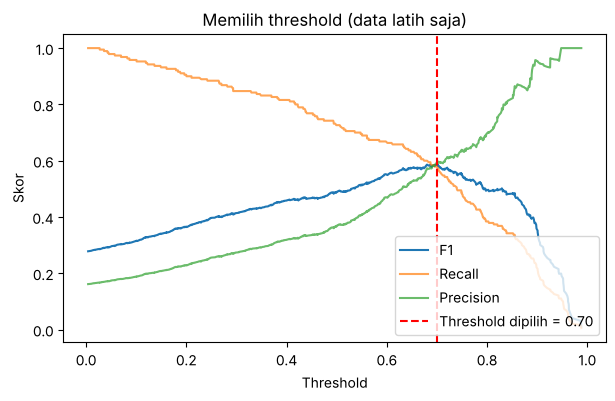

Threshold terpilih: 0.70


In [21]:
proba_oof = cross_val_predict(pipe_terbaik, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

presisi, recall, ambang = precision_recall_curve(y_train, proba_oof)
f1_per_ambang = 2 * presisi[:-1] * recall[:-1] / (presisi[:-1] + recall[:-1] + 1e-9)
THRESHOLD = float(ambang[np.argmax(f1_per_ambang)])

plt.plot(ambang, f1_per_ambang, label="F1")
plt.plot(ambang, recall[:-1], label="Recall", alpha=0.7)
plt.plot(ambang, presisi[:-1], label="Precision", alpha=0.7)
plt.axvline(THRESHOLD, color="red", linestyle="--", label=f"Threshold dipilih = {THRESHOLD:.2f}")
plt.xlabel("Threshold"); plt.ylabel("Skor"); plt.title("Memilih threshold (data latih saja)")
plt.legend(); plt.show()

print(f"Threshold terpilih: {THRESHOLD:.2f}")

**Cara membaca grafik:** semakin kecil threshold, semakin banyak karyawan yang kita tandai berisiko (Recall naik, tapi Precision turun, karena lebih banyak salah tuduh). Semakin besar threshold, kita makin selektif (Precision naik, tapi Recall turun). Garis merah adalah titik seimbang menurut F1.

> ℹ️ Karena model memakai `class_weight="balanced"`, probabilitasnya cenderung "digelembungkan" untuk kelas langka. Itu sebabnya threshold terbaik bisa muncul di atas 0,5.

> 💡 Dalam praktik, threshold bisa disesuaikan dengan kebutuhan HR. Kalau biaya kehilangan karyawan sangat besar, pilih threshold lebih kecil agar lebih banyak karyawan berisiko terpantau.

## 9️⃣ Ujian Akhir: Evaluasi di Data Uji

Inilah saatnya membuka "soal ujian asli". Model dilatih pada **seluruh data latih**, lalu diuji **satu kali** pada data uji.

Kita bandingkan dua cara memutuskan:
- **Threshold 0,5** (bawaan)
- **Threshold terpilih** (dari langkah 8)

Sebagai pembanding, ada juga **"Tebak semua No"** untuk melihat apakah model kita benar-benar lebih baik dari menebak asal.

In [22]:
pipe_terbaik.fit(X_train, y_train)
proba_test = pipe_terbaik.predict_proba(X_test)[:, 1]

def ringkas(nama, pred):
    return {"Cara": nama,
            "Akurasi":   (pred == y_test).mean(),
            "Recall":    recall_score(y_test, pred),
            "Precision": precision_score(y_test, pred, zero_division=0),
            "F1":        f1_score(y_test, pred)}

tabel = pd.DataFrame([
    ringkas("Tebak semua 'No'", np.zeros(len(y_test), dtype=int)),
    ringkas("Model, threshold 0.5", (proba_test >= 0.5).astype(int)),
    ringkas(f"Model, threshold {THRESHOLD:.2f}", (proba_test >= THRESHOLD).astype(int)),
]).set_index("Cara").round(3)
display(tabel)

print(f"ROC-AUC data uji : {roc_auc_score(y_test, proba_test):.3f}")
print(f"PR-AUC  data uji : {average_precision_score(y_test, proba_test):.3f}")

,Akurasi,Recall,Precision,F1
Cara,,,,
Tebak semua 'No',0.840,0.000,0.000,0.000
"Model, threshold 0.5",0.793,0.745,0.417,0.534
"Model, threshold 0.70",0.847,0.404,0.528,0.458


ROC-AUC data uji : 0.807
PR-AUC  data uji : 0.550


**Cara membaca tabel:**
- Perhatikan baris *"Tebak semua No"*: akurasinya tinggi, tetapi **Recall = 0**, artinya tidak menemukan satu pun karyawan yang akan keluar.
- Model yang baik harus punya **Recall dan F1 jauh lebih tinggi** dari baris itu, meskipun akurasinya bisa sedikit turun. Itu wajar dan justru yang kita inginkan.

Berikutnya laporan lengkap dan *confusion matrix* (tabel benar/salah tebakan).

              precision    recall  f1-score   support

Bertahan (0)       0.89      0.93      0.91       247
  Keluar (1)       0.53      0.40      0.46        47

    accuracy                           0.85       294
   macro avg       0.71      0.67      0.68       294
weighted avg       0.83      0.85      0.84       294



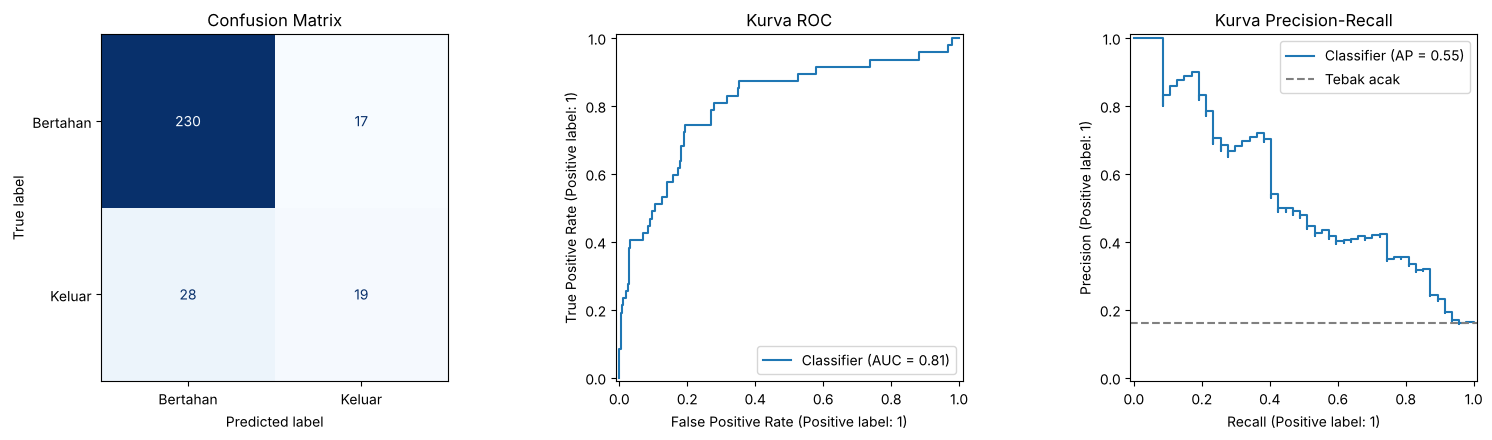

In [23]:
pred_akhir = (proba_test >= THRESHOLD).astype(int)

print(classification_report(y_test, pred_akhir, target_names=["Bertahan (0)", "Keluar (1)"]))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_akhir),
                       display_labels=["Bertahan", "Keluar"]).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Confusion Matrix")
RocCurveDisplay.from_predictions(y_test, proba_test, ax=axes[1])
axes[1].set_title("Kurva ROC")
PrecisionRecallDisplay.from_predictions(y_test, proba_test, ax=axes[2])
axes[2].axhline(y_test.mean(), color="gray", linestyle="--", label="Tebak acak")
axes[2].legend(); axes[2].set_title("Kurva Precision-Recall")
plt.tight_layout(); plt.show()

**Cara membaca *confusion matrix*** (kotak 2×2):

| | Ditebak Bertahan | Ditebak Keluar |
|---|---|---|
| **Sebenarnya Bertahan** | ✅ Benar | ❌ Salah alarm |
| **Sebenarnya Keluar** | ❌ Terlewat (paling merugikan) | ✅ Berhasil tertangkap |

- **Kurva ROC:** semakin melengkung ke kiri atas, semakin bagus (garis diagonal = menebak acak).
- **Kurva Precision-Recall:** semakin jauh di atas garis putus-putus abu-abu, semakin bagus.

## 📊 Rekap Akurasi Kedua Model

Bagian ini merangkum **akurasi** kedua model di satu tempat, sekaligus mengecek apakah memenuhi syarat minimal **50%**.

- **Akurasi CV**: rata-rata akurasi dari cross-validation di data latih.
- **Akurasi Data Uji**: akurasi pada data uji yang belum pernah dilihat model.
- Kedua model memakai threshold bawaan **0,5** supaya perbandingannya adil. Model terpilih yang memakai threshold hasil penyetelan (langkah 8) sudah dinilai di bagian 9.

> ℹ️ Tabel ini hanya untuk **pelaporan**. Pemilihan model sudah dilakukan lebih dulu lewat cross-validation, jadi data uji tidak dipakai untuk memilih.

In [24]:
SYARAT_AKURASI = 0.50   # syarat minimal akurasi

rekap = []
for nama, model in models.items():
    pipa = Pipeline([("prep", preprocessor), ("model", model)])
    pipa.fit(X_train, y_train)
    pred = pipa.predict(X_test)                      # threshold bawaan 0.5
    rekap.append({"Model": nama, "Threshold": "0.5 (bawaan)",
                  "Akurasi CV": hasil_cv.loc[nama, "Akurasi"],
                  "Akurasi Data Uji": accuracy_score(y_test, pred),
                  "Recall": recall_score(y_test, pred),
                  "F1": f1_score(y_test, pred)})

rekap_df = pd.DataFrame(rekap).set_index("Model")
tampil = rekap_df.copy()
for k in ["Akurasi CV", "Akurasi Data Uji", "Recall", "F1"]:
    tampil[k] = tampil[k].apply(lambda v: round(v, 3) if not isinstance(v, str) else v)
display(tampil)

print(f"Syarat akurasi minimal: {SYARAT_AKURASI*100:.0f}%\n")
for nama, baris_ in rekap_df.iterrows():
    akurasi = baris_["Akurasi Data Uji"]
    status = "✅ memenuhi" if akurasi >= SYARAT_AKURASI else "❌ belum memenuhi"
    print(f"{nama:<35} akurasi uji = {akurasi*100:5.1f}%  -> {status}")

,Threshold,Akurasi CV,Akurasi Data Uji,Recall,F1
Model,,,,,
Logistic Regression,0.5 (bawaan),0.756,0.793,0.745,0.534
Random Forest,0.5 (bawaan),0.867,0.844,0.362,0.425


Syarat akurasi minimal: 50%

Logistic Regression                 akurasi uji =  79.3%  -> ✅ memenuhi
Random Forest                       akurasi uji =  84.4%  -> ✅ memenuhi


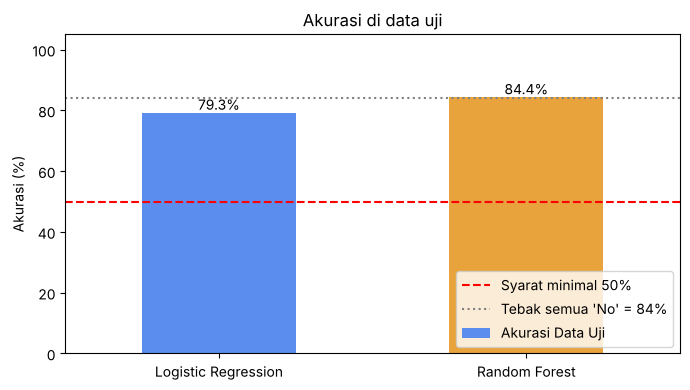

In [25]:
baseline = 1 - y_test.mean()
warna = ["#5B8DEF", "#E8A33D", "#4C9F70"]
ax = (rekap_df["Akurasi Data Uji"] * 100).plot(kind="bar", color=warna[:len(rekap_df)], rot=0)
ax.axhline(SYARAT_AKURASI * 100, color="red", linestyle="--", label="Syarat minimal 50%")
ax.axhline(baseline * 100, color="gray", linestyle=":", label=f"Tebak semua 'No' = {baseline*100:.0f}%")
for i, v in enumerate(rekap_df["Akurasi Data Uji"] * 100):
    ax.text(i, v + 1, f"{v:.1f}%", ha="center")
ax.set_ylim(0, 105); ax.set_ylabel("Akurasi (%)"); ax.set_xlabel("")
ax.set_title("Akurasi di data uji"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

**Cara membaca:**
- Semua model berada **di atas garis merah (50%)**, jadi syarat minimal akurasi terpenuhi.
- Perhatikan garis abu-abu: menebak "semua karyawan bertahan" saja sudah menghasilkan akurasi setinggi itu. Karena itu akurasi **tidak boleh berdiri sendiri**. Lihat juga **Recall** (berapa banyak karyawan yang akan keluar berhasil terdeteksi) dan **F1**.
- Model dengan akurasi tinggi tetapi Recall sangat rendah berarti hanya jago menebak "bertahan", dan itu tidak berguna untuk tujuan kita.

## 🔟 Faktor Apa yang Paling Berpengaruh?

Kita ingin tahu fitur mana yang paling membantu model. Kita pakai **Permutation Importance**:

> Acak-acak nilai satu kolom di data uji. Kalau performa model **turun banyak**, berarti kolom itu penting. Kalau hampir tidak berubah, kolom itu kurang berguna.

Metode ini bekerja pada kolom asli (misalnya `OverTime`), jadi hasilnya mudah dibaca.

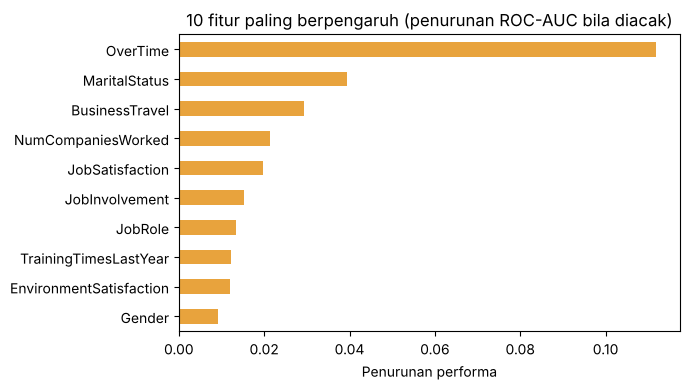

In [26]:
hasil_pi = permutation_importance(pipe_terbaik, X_test, y_test, scoring="roc_auc",
                                  n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)

penting = pd.Series(hasil_pi.importances_mean, index=X_test.columns).sort_values(ascending=False).head(10)

penting.sort_values().plot(kind="barh", color="#E8A33D")
plt.title("10 fitur paling berpengaruh (penurunan ROC-AUC bila diacak)")
plt.xlabel("Penurunan performa")
plt.tight_layout(); plt.show()

**Catatan penting:** pola ini menunjukkan *keterkaitan*, bukan *sebab-akibat*. Misalnya, lembur memang berkaitan dengan risiko keluar yang lebih tinggi, tetapi itu belum tentu berarti lembur adalah satu-satunya penyebab. Gunakan hasil ini sebagai petunjuk awal untuk diskusi dengan tim HR.

## 1️⃣1️⃣ Menyimpan Model

Kita simpan **seluruh pipeline** (preprocessing + model) beserta threshold ke satu file. Jadi saat dipakai nanti, data baru otomatis melewati langkah preprocessing yang **persis sama** dengan saat training, tanpa perlu menyimpan scaler atau encoder secara terpisah.

In [ ]:
paket_model = {
    "pipeline": pipe_terbaik,
    "threshold": THRESHOLD,
    "kolom": X_train.columns.tolist(),
    "nama_model": nama_terbaik,
    # Profil data latih: dipakai saat inferensi untuk mendeteksi data baru yang "asing"
    "rentang_numerik": {c: (float(X_train[c].min()), float(X_train[c].max())) for c in kolom_numerik},
    "kategori_dikenal": {c: sorted(X_train[c].astype(str).unique().tolist()) for c in kolom_kategori},
}
joblib.dump(paket_model, "model_attrition.joblib")
print("Model tersimpan di: model_attrition.joblib ✅")

## 1️⃣2️⃣ Inferensi Model: Menguji Data Baru di Luar Data Latih

**Inferensi** di sini artinya memakai model yang sudah jadi untuk memprediksi **data karyawan baru**, yaitu data yang tidak pernah dipakai untuk melatih maupun menguji model. Bagian ini sengaja dibuat **berdiri sendiri**: cukup file `model_attrition.joblib` dan file data baru, tanpa perlu menjalankan ulang proses training.

| Langkah | Yang dilakukan |
|---|---|
| 1. Muat model | Membaca pipeline, threshold, dan daftar kolom dari `model_attrition.joblib` |
| 2. Baca data baru | File CSV berisi karyawan yang ingin diperiksa (format sama dengan data asli) |
| 3. Validasi | Cek kolom wajib, nilai kosong, serta nilai atau kategori yang tidak pernah dilihat saat training |
| 4. Prediksi | Peluang keluar, keputusan (memakai threshold terpilih), dan tingkat risiko |
| 5. Evaluasi (opsional) | Jika data baru punya kolom `Attrition` yang sebenarnya, hitung seberapa tepat tebakan model |
| 6. Simpan hasil | Tabel hasil diekspor ke CSV |

> ℹ️ Kolom tambahan di data baru (misalnya `EmployeeNumber`, `Attrition`, atau kolom konstan) **tidak masalah**. Model hanya mengambil kolom yang ia butuhkan.

### 12.1 Fungsi inferensi

Dua fungsi inti:
- `periksa_data_baru()`: memeriksa data **sebelum** diprediksi. Masalah fatal (kolom kurang, ada nilai kosong, kolom angka berisi teks) menghentikan proses dengan pesan jelas. Data yang "asing" (angka di luar rentang data latih atau kategori baru) hanya diberi **peringatan**, karena prediksinya tetap bisa dihitung tetapi kurang bisa dipercaya.
- `prediksi_batch()`: memprediksi banyak karyawan sekaligus.

**Tingkat risiko:** *Tinggi* = peluang di atas threshold; *Sedang* = antara setengah threshold dan threshold (perlu dipantau); *Rendah* = di bawahnya.

In [ ]:
import os

NAMA_FILE_MODEL = "model_attrition.joblib"
KOLOM_TARGET = "Attrition"

def muat_model(path=NAMA_FILE_MODEL):
    return joblib.load(path)

def periksa_data_baru(df_baru, paket):
    """Validasi data baru. Mengembalikan (data siap prediksi, daftar peringatan)."""
    kolom = paket["kolom"]
    kurang = [k for k in kolom if k not in df_baru.columns]
    if kurang:
        raise ValueError(f"Kolom berikut belum ada di data baru: {kurang}")

    data = df_baru[kolom].copy()

    kosong = data.isnull().sum()
    kosong = kosong[kosong > 0]
    if len(kosong):
        raise ValueError(f"Ada nilai kosong, lengkapi dulu: {kosong.to_dict()}")

    rentang = paket.get("rentang_numerik", {})
    for c in rentang:
        if not pd.api.types.is_numeric_dtype(data[c]):
            raise ValueError(f"Kolom '{c}' harus berisi angka.")

    peringatan = []
    for c, (lo, hi) in rentang.items():
        n_luar = int(((data[c] < lo) | (data[c] > hi)).sum())
        if n_luar:
            peringatan.append(f"{c}: {n_luar} baris di luar rentang data latih ({lo:g} sampai {hi:g})")
    for c, dikenal in paket.get("kategori_dikenal", {}).items():
        asing = sorted(set(data[c].astype(str)) - set(dikenal))
        if asing:
            peringatan.append(f"{c}: kategori baru {asing} (tidak ada di data latih, akan diabaikan encoder)")
    return data, peringatan

def prediksi_batch(df_baru, path_model=NAMA_FILE_MODEL, tampilkan_peringatan=True):
    """Prediksi banyak karyawan baru sekaligus. Kolom asli tetap dipertahankan."""
    paket = muat_model(path_model)
    data, peringatan = periksa_data_baru(df_baru, paket)
    if tampilkan_peringatan:
        for p in peringatan:
            print("⚠️", p)

    peluang = paket["pipeline"].predict_proba(data)[:, 1]
    thr = paket["threshold"]

    hasil = df_baru.copy()
    hasil["Peluang_Keluar_%"] = (peluang * 100).round(1)
    hasil["Prediksi"] = np.where(peluang >= thr, "Berisiko keluar", "Cenderung bertahan")
    hasil["Tingkat_Risiko"] = np.select([peluang >= thr, peluang >= thr * 0.5], ["Tinggi", "Sedang"], default="Rendah")
    return hasil

def prediksi_attrition(data_karyawan: dict):
    """Prediksi satu karyawan (dictionary)."""
    r = prediksi_batch(pd.DataFrame([data_karyawan])).iloc[0]
    return {"peluang_keluar_%": float(r["Peluang_Keluar_%"]), "keputusan": r["Prediksi"], "tingkat_risiko": r["Tingkat_Risiko"]}

paket_cek = muat_model()
print(f"Model dimuat   : {paket_cek['nama_model']} | threshold = {paket_cek['threshold']:.2f}")
print(f"Kolom dibutuhkan ({len(paket_cek['kolom'])}):", paket_cek["kolom"])

### 12.2 Baca data karyawan baru

Siapkan file CSV **data karyawan baru** (isinya karyawan yang belum pernah dilihat model), lalu isi `DATA_BARU_PATH` di sel di bawah. Aturannya:
- Nama kolom harus sama dengan data asli (cukup 15 kolom yang dibutuhkan model, kolom lain boleh ada).
- Kolom `Attrition` **boleh ada** (jika ada, hasil akan dievaluasi) atau **boleh tidak ada** (jika karyawannya belum tahu keluar atau tidak).

> 💡 **Belum punya file data baru?** Jalankan sel di bawah apa adanya. Jika file tidak ditemukan, notebook membuat **`template_data_baru.csv`** (berisi 15 kolom yang diperlukan dan beberapa baris contoh) dan memakai baris contoh itu sebagai **demo**. Ganti isinya dengan data karyawan Anda, lalu jalankan ulang. Baris demo berasal dari data uji, jadi **belum benar-benar "baru"**; hasil yang sebenarnya baru muncul setelah Anda memakai file Anda sendiri.

In [ ]:
DATA_BARU_PATH = "data_karyawan_baru.csv"     # ubah ke file data baru Anda

# Pakai Google Colab? Hapus tanda # di dua baris berikut untuk mengunggah file:
# from google.colab import files
# files.upload()

if os.path.exists(DATA_BARU_PATH):
    df_baru = pd.read_csv(DATA_BARU_PATH, sep=None, engine="python", encoding="utf-8-sig")
    print(f"Data baru dibaca dari '{DATA_BARU_PATH}': {df_baru.shape[0]} karyawan, {df_baru.shape[1]} kolom")
    MODE_DEMO = False
else:
    print(f"File '{DATA_BARU_PATH}' tidak ditemukan -> memakai MODE DEMO.")
    template = X_test[paket_cek["kolom"]].head(5).reset_index(drop=True)
    template.to_csv("template_data_baru.csv", index=False)
    print("Template kolom tersimpan di: template_data_baru.csv (isi dengan karyawan baru, simpan sebagai", DATA_BARU_PATH + ")")
    df_baru = template.copy()
    MODE_DEMO = True

display(df_baru.head())

### 12.3 Jalankan prediksi pada data baru

Setiap karyawan mendapat **peluang keluar**, **keputusan** (berdasarkan threshold hasil langkah 8), dan **tingkat risiko**. Tabel diurutkan dari yang paling berisiko supaya HR bisa langsung melihat siapa yang perlu didahulukan.

In [ ]:
hasil_baru = prediksi_batch(df_baru)

kolom_id = [c for c in ["EmployeeNumber"] if c in hasil_baru.columns]
kolom_hasil = ["Peluang_Keluar_%", "Prediksi", "Tingkat_Risiko"]
tampil = hasil_baru[kolom_id + kolom_hasil].sort_values("Peluang_Keluar_%", ascending=False)
display(tampil.reset_index(drop=True))

print("Ringkasan:")
print(hasil_baru["Tingkat_Risiko"].value_counts().reindex(["Tinggi", "Sedang", "Rendah"], fill_value=0).to_string())
print(f"\nBerisiko keluar menurut model: {(hasil_baru['Prediksi'] == 'Berisiko keluar').sum()} dari {len(hasil_baru)} karyawan")

### 12.4 Evaluasi (hanya jika data baru punya kolom `Attrition`)

Jika data baru sudah punya jawaban sebenarnya (`Yes`/`No`), kita bisa menilai seberapa tepat model pada data yang benar-benar baru. Metrik yang dilihat sama seperti sebelumnya: **Recall, Precision, F1**, dan *confusion matrix*. Jika kolom `Attrition` tidak ada, sel ini otomatis dilewati.

> ⚠️ Jika jumlah karyawan baru sedikit atau hanya sedikit yang keluar, angka metrik mudah berubah-ubah. Jangan menarik kesimpulan kuat dari puluhan baris.

In [ ]:
if KOLOM_TARGET in df_baru.columns:
    y_baru = df_baru[KOLOM_TARGET].map({"Yes": 1, "No": 0, 1: 1, 0: 0})
    if y_baru.isnull().any():
        print(f"Kolom {KOLOM_TARGET} berisi nilai selain Yes/No (atau 1/0), evaluasi dilewati.")
    else:
        pred_baru = (hasil_baru["Prediksi"] == "Berisiko keluar").astype(int)
        peluang_baru = hasil_baru["Peluang_Keluar_%"] / 100

        print(f"Jumlah karyawan baru: {len(y_baru)} | yang benar-benar keluar: {int(y_baru.sum())}\n")
        print(classification_report(y_baru, pred_baru, labels=[0, 1],
                                    target_names=["Bertahan (0)", "Keluar (1)"], zero_division=0))
        if y_baru.nunique() == 2:
            print(f"ROC-AUC: {roc_auc_score(y_baru, peluang_baru):.3f} | PR-AUC: {average_precision_score(y_baru, peluang_baru):.3f}")
        else:
            print("ROC-AUC dan PR-AUC dilewati karena data baru hanya berisi satu kelas.")

        ConfusionMatrixDisplay(confusion_matrix(y_baru, pred_baru, labels=[0, 1]),
                               display_labels=["Bertahan", "Keluar"]).plot(cmap="Blues", colorbar=False)
        plt.title("Confusion Matrix: data baru")
        plt.show()
else:
    print(f"Data baru tidak punya kolom '{KOLOM_TARGET}', jadi hanya prediksi yang dihasilkan (tidak ada evaluasi).")

### 12.5 Simpan hasil prediksi

Hasil disimpan ke CSV (dengan `utf-8-sig` supaya terbaca benar di Excel).

In [ ]:
FILE_HASIL = "hasil_prediksi_attrition.csv"
hasil_baru.to_csv(FILE_HASIL, index=False, encoding="utf-8-sig")
print(f"Hasil prediksi tersimpan di: {FILE_HASIL} ✅")

# Pakai Google Colab? Hapus tanda # untuk mengunduh file hasil:
# from google.colab import files
# files.download(FILE_HASIL)

### 12.6 Mencoba satu karyawan secara manual

Untuk memeriksa satu orang saja, isi data dalam bentuk *dictionary* (semua kolom wajib terisi). Di bawah, kita ambil satu baris dari data baru sebagai contoh, lalu membuat versi "berisiko" dengan mengubah beberapa kondisi: sering lembur, kepuasan kerja rendah, lajang, dan tanpa opsi saham.

In [ ]:
def tampilkan(judul, hasil):
    print("=" * 45)
    print(judul)
    print("=" * 45)
    print(f"Peluang keluar : {hasil['peluang_keluar_%']}%")
    print(f"Keputusan      : {hasil['keputusan']}")
    print(f"Tingkat risiko : {hasil['tingkat_risiko']}\n")

contoh_biasa = df_baru.iloc[0][paket_cek["kolom"]].to_dict()

# Hanya kolom yang masih dipakai model yang diubah (fitur yang dibuang di bagian 5.2 tidak dibutuhkan lagi)
perubahan_berisiko = {"OverTime": "Yes", "JobSatisfaction": 1, "EnvironmentSatisfaction": 1,
                      "StockOptionLevel": 0, "MaritalStatus": "Single"}
contoh_berisiko = {**contoh_biasa, **{k: v for k, v in perubahan_berisiko.items() if k in paket_cek["kolom"]}}

tampilkan("Karyawan contoh (data asli baris pertama)", prediksi_attrition(contoh_biasa))
tampilkan("Karyawan contoh (kondisi berisiko)", prediksi_attrition(contoh_berisiko))